# Backtest Autopsy #1: a random forest on the direction of a smoothed price

**Tags:** proxy target (not yet in the taxonomy; closest existing tag: leakage), cost model (secondary)

> **Scope.** This notebook is a simplified implementation of the idea: a compact feature set and a plain unit-notional backtest, with the parameter values listed in the settings cell. The verdict applies to the version tested.

## TL;DR

* **Idea.** Predict whether the average price over the next 5 days will sit above or below today's 5-day average, with a random forest per FX pair, refit on a rolling window with purge and embargo. Trade the predicted sign.
* **What looked good.** On *label accuracy* the model beats two mechanical baselines (trailing slope and "yesterday's return sign"): pooled accuracy 68.4% against 61.8% for the lag-1 rule, a lift of +6.7 points.
* **Verdict number.** The signal's correlation with the **next-day return you actually earn** is +0.0026 and its pooled gross (before cost) annualised Sharpe is **+0.07** with a block-bootstrap 90% interval of [-0.23, +0.40]; net of the observed spread the Sharpe is -0.18. On an illustrative initial equity of 100,000 USD the gross P&L over 5,838 days is 5,892 USD, costs 27,499 USD and net P&L -21,606 USD.
* **Killing test.** Score the traded outcome, not the label: signal-to-next-day-return relation, a block bootstrap, a sign-permutation test and a cost sweep.
* **Note.** The initial equity of 100,000 USD is an illustrative assumption; section 9 sweeps 5,000 to 250,000 USD.

Outputs below come from a run on real data (not redistributed). With `AUTOPSY_SYNTHETIC=1` the notebook runs end to end on a synthetic panel and does **not** reproduce the failure; a synthetic random walk can still show a nonzero gross Sharpe on one path by pure luck, which is why synthetic mode prints a multi-seed table in section 8.

### Prerequisites

* Python 3.10+, `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, and the shared package `autopsy_common` (`pip install -e ../..`).
* Familiarity with: moving averages, classification accuracy vs a baseline, rolling walk-forward with purge/embargo, gross vs net P&L.
* Data: your own daily bars with the schema in section 2, in a folder named by `AUTOPSY_DATA_DIR` (file `daily_bars.parquet`).

## 1. Settings (control panel)

One dictionary for every constant. The values below are the starting point for this case. Change them and re-run the test to see whether the verdict holds. Two environment variables pick the mode: `AUTOPSY_SYNTHETIC=1` for a synthetic panel, otherwise `AUTOPSY_DATA_DIR` must point at the folder with `daily_bars.parquet`.

In [1]:
from __future__ import annotations

import os
import time
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier

from autopsy_common.data import load_daily_panel, use_synthetic
from autopsy_common.features import price_features
from autopsy_common.metrics import block_bootstrap_sharpe, sharpe_ratio
from autopsy_common.perf import performance_summary, rolling_sharpe
from autopsy_common.plots import (plot_bar_contribution, plot_capital_sweep, plot_cost_decomposition,
                                  plot_drawdown, plot_equity, plot_exposure_turnover, plot_monthly_heatmap,
                                  plot_return_distribution, plot_rolling_risk, plot_yearly_bars)
from autopsy_common.schema import check_schema
from autopsy_common.sweep import capital_sweep, scale_returns_to_equity
from autopsy_common.synthetic import PANEL_KEY, PANEL_SCHEMA, synthetic_daily_panel
from autopsy_common.walkforward import walk_forward_windows

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
SYNTHETIC = use_synthetic()
RESULTS: Dict[str, object] = {}

PARAMS = dict(
    capital=100_000.0,        # illustrative initial equity in USD (an assumption; see section 9)
    sma_k=5,                  # the label compares the next-k-day average with the last-k-day average
    min_train=500,            # first refit after this many rows
    step=21,                  # refit every 21 rows (about a month)
    train_span=750,           # rolling training window length in rows
    embargo=1,                # rows skipped between the refit point and the test segment
    n_estimators=100, max_depth=5, min_samples_leaf=10, class_weight="balanced",
    seed=0,
    features=["ret_1d", "ret_3d", "ret_5d", "mom_5_20", "rvol_10d", "range_frac",
              "trend_spread", "zscore_10", "rsi_14", "ewma_vol"],
    bootstrap_block=10, bootstrap_iters=1000, permutation_draws=300,
    cost_multiples=(0.0, 0.25, 0.5, 1.0, 2.0),
    periods_per_year=252,
    capital_grid=(5_000, 10_000, 25_000, 50_000, 100_000, 250_000),
)
N_SYNTH_DAYS = 1600
SYNTH_ASSETS = ["P1", "P2", "P3"]
print(f"mode: {'SYNTHETIC' if SYNTHETIC else 'REAL DATA'}")

mode: REAL DATA


## 2. Data

### 2.1 Source recipe

* **Vendor / product:** minute-level bid and ask quotes for six liquid USD-based FX pairs from Interactive Brokers (FX bid/ask export); terms of use and redistribution rights are not verified.
* **Frequency:** the strategy uses **daily** bars built from the minute data with a fixed end-of-day cut.
* **Time zone:** the minute timestamps are naive in a fixed UTC-5 offset; the daily cut is on that clock.
* **How to rebuild:** resample bid and ask closes to the last value per day, mid = (bid + ask) / 2, daily spread = mean of (ask - bid) over the day's bars, high and low of the mid.

### 2.2 Rows, key and columns

* **Row definition:** one pair on one calendar day. **Key** `(date, asset)`, unique; **sort** ascending by that tuple. Nulls: rows without a close are dropped upstream; no nulls remain.
* In this notebook pair names are replaced by `P1..Pn` so that nothing depends on a particular instrument.

| Column | dtype | Meaning | Units |
|---|---|---|---|
| `date` | datetime | calendar day of the daily bar | day |
| `asset` | string | pair label (anonymised) | n/a |
| `asset_class` | string | instrument group | n/a |
| `high` | float64 | highest mid of the day | quote currency |
| `low` | float64 | lowest mid of the day | quote currency |
| `close` | float64 | last mid of the day | quote currency |
| `spread` | float64 | mean bid-ask spread over the day's bars | quote currency |

In [2]:
CASE_COLS = ["date", "asset", "asset_class", "high", "low", "close", "spread"]
CASE_SCHEMA = {c: PANEL_SCHEMA[c] for c in CASE_COLS}

panel = load_daily_panel(CASE_SCHEMA, SYNTH_ASSETS, n_days=N_SYNTH_DAYS)
if not SYNTHETIC:  # anonymise labels: P1..Pn in sorted order
    alias = {a: f"P{i + 1}" for i, a in enumerate(sorted(panel["asset"].unique()))}
    panel["asset"] = panel["asset"].map(alias)
    panel = panel.sort_values(PANEL_KEY).reset_index(drop=True)

print("no nulls in any column:", not bool(panel.isna().any().any()))
print("key unique:", bool(panel.duplicated(PANEL_KEY).sum() == 0), "| sorted by key:", bool(panel.set_index(PANEL_KEY).index.is_monotonic_increasing))
print("schema check passed:", check_schema(panel, CASE_SCHEMA, PANEL_KEY))
for broken, expect in [(panel.drop(columns=["close"]), "Missing columns"),
                       (panel.assign(spread=panel["spread"].astype("float32")), "Wrong dtypes")]:
    try:
        check_schema(broken, CASE_SCHEMA, PANEL_KEY)
        raise AssertionError("schema check did not fail")
    except ValueError as e:
        assert expect in str(e)
print("negative schema checks raise ValueError as intended")

no nulls in any column: True
key unique: True | sorted by key: True
schema check passed: True
negative schema checks raise ValueError as intended


## 3. Step 1: features and the label

### 3.1 Causal features

`autopsy_common.features.price_features` builds, for each pair, short returns (1, 3, 5 days), a 5-vs-20-day momentum gap, realised and EWMA volatility, the high-low range as a share of the close, a fast/slow moving-average spread, a 10-day z-score and a 14-day RSI. **Every column at row `t` uses data up to and including `t`.** What can go wrong: a rolling window that is centred, or a shift in the wrong direction, silently leaks the future; a unit test on a known series (see the repository tests) is the cheap guard.

### 3.2 The label

`label[t] = sign(mean(close[t+1..t+k]) - mean(close[t-k+1..t]))` with `k = 5`. It asks: will the *next* five-day average sit above or below the *last* five-day average? Two properties matter and both are traps:

* **Forward reach.** The label at `t` uses closes up to `t + k`, so a training row's label overlaps the test segment unless a purge of at least `k` rows is applied (section 4).
* **A smoothed target is partly known already.** Each moving average shares four of its five closes with its neighbour one day later. The label is therefore dominated by information that exists at time `t`, so a model can score well on it without knowing anything about *tomorrow's* return. This is the central point of the case.

In [3]:
def sma_direction_label(close: pd.Series, k: int) -> pd.Series:
    """label[t] = sign(mean(close[t+1..t+k]) - mean(close[t-k+1..t])).
    NaN where either window is undefined. Its furthest forward reach is t+k."""
    sma = close.rolling(k, min_periods=k).mean()
    return np.sign(sma.shift(-k) - sma)


def build_frames(panel: pd.DataFrame, k: int) -> Dict[str, pd.DataFrame]:
    out = {}
    for asset, g in panel.groupby("asset"):
        g = g.set_index("date")
        f = price_features(g)
        f["close"], f["spread"] = g["close"], g["spread"]
        f["label"] = sma_direction_label(g["close"], k)
        out[asset] = f
    return out


frames = build_frames(panel, PARAMS["sma_k"])
FEATURES = PARAMS["features"]
print(f"features: {len(FEATURES)} | label reach: {PARAMS['sma_k']} rows")

features: 10 | label reach: 5 rows


## 4. Step 2: the model and the walk-forward loop

One random forest per pair (100 shallow trees, balanced classes). Every `step = 21` rows the forest is refit on the trailing `train_span = 750` rows ending `purge` rows before the refit point, and predicts the next 21 rows after a 1-row embargo.

* **Purge = k = 5 rows.** The last training row `r` satisfies `r + 5 < refit`, so its label (which looks 5 rows ahead) does not reach into rows where predictions are used.
* **Rows with label 0** (exactly equal averages) are dropped from training.
* **Why a rolling, not expanding, window:** FX regimes drift; a rolling window forgets the old ones. It is also a hyperparameter you can change and re-test.

What can go wrong: a purge shorter than the label's reach is the classic leak and yields spectacular, fake accuracy; the walk-forward code is covered by a unit test in the shared package.

In [4]:
def walk_forward_rf(frames: Dict[str, pd.DataFrame], params: dict):
    """One RandomForest per asset, refit every `step` rows on a rolling window.
    Returns (signals, importances): signals[asset] is a +1/-1 Series, OOS only."""
    purge = int(params["sma_k"])
    signals: Dict[str, List[pd.Series]] = {a: [] for a in frames}
    imps: List[pd.Series] = []
    for asset, f in frames.items():
        for tr_s, tr_e, te_s, te_e in walk_forward_windows(len(f), params["min_train"], params["step"], purge,
                                                           params["embargo"], params["train_span"]):
            train = f.iloc[tr_s:tr_e][FEATURES + ["label"]].dropna()
            train = train[train["label"] != 0]
            if len(train) < 200 or train["label"].nunique() < 2:
                continue
            m = RandomForestClassifier(n_estimators=params["n_estimators"], max_depth=params["max_depth"],
                                       min_samples_leaf=params["min_samples_leaf"],
                                       class_weight=params["class_weight"], random_state=params["seed"], n_jobs=-1)
            m.fit(train[FEATURES], train["label"])
            imps.append(pd.Series(m.feature_importances_, index=FEATURES))
            test = f.iloc[te_s:te_e][FEATURES].dropna()
            if len(test):
                signals[asset].append(pd.Series(m.predict(test), index=test.index))
    sig = {a: pd.concat(v).sort_index() for a, v in signals.items() if v}
    return sig, imps


_t0 = time.time()
signals, importances = walk_forward_rf(frames, PARAMS)
print(f"assets with out-of-sample signals: {len(signals)} | walk-forward time: {time.time() - _t0:.0f}s")

assets with out-of-sample signals: 6 | walk-forward time: 277s


## 5. Step 3: from a signal to P&L (sizing and costs)

* **Position.** The signal at the close of day `t` (+1 or -1) is held over day `t+1` at **unit notional**: each pair gets an equal share of the initial equity (`capital / n_pairs`), and the portfolio return is the equal-weight average of the per-pair returns. No leverage, no compounding between pairs.
* **Cost.** A change in position pays `|delta| x spread / close`, the observed daily mean spread as a fraction of price. A flip from long to short is `|delta| = 2`. No commission or minimum ticket is modelled: costs here are purely proportional (section 9).
* **Equity.** The USD equity path is `capital x cumulative product (1 + portfolio return)`.

The same function scores two mechanical rules on the **same dates** as the model: a moving-average trend rule (sign of the fast/slow spread) and a lag-1 rule (sign of yesterday's return). They are the yardsticks the model must beat.

In [5]:
def unit_backtest(frames, signals, cost_multiple: float = 1.0) -> Dict[str, pd.DataFrame]:
    """Signal at close t is held over day t+1 at unit notional. A position change
    pays |delta| * cost_multiple * spread / close. Returns per-asset gross, cost
    and position frames (OOS dates only) plus the equal-weight pooled series."""
    gross, cost, pos_all = {}, {}, {}
    for asset, s in signals.items():
        f = frames[asset]
        pos = s.reindex(f.index).ffill().fillna(0.0)
        ret_next = f["close"].pct_change().shift(-1)
        g = (pos * ret_next).loc[s.index].dropna()
        c = (pos.diff().abs().fillna(0.0) * cost_multiple * f["spread"] / f["close"]).loc[g.index]
        gross[asset], cost[asset], pos_all[asset] = g, c, pos.loc[g.index]
    G, C, P = pd.DataFrame(gross), pd.DataFrame(cost), pd.DataFrame(pos_all)
    return {"gross_by_asset": G, "cost_by_asset": C, "position": P,
            "gross": G.mean(axis=1), "cost": C.mean(axis=1), "net": (G - C).mean(axis=1)}


def trend_rule_signals(frames, like):
    """Moving-average trend rule (sign of the fast/slow spread) on the same dates as `like`."""
    return {a: np.sign(frames[a]["trend_spread"]).loc[s.index].replace(0.0, np.nan).ffill().dropna() for a, s in like.items()}


def lag1_rule_signals(frames, like):
    """Trade the sign of yesterday's return on the same dates as `like`."""
    return {a: np.sign(frames[a]["close"].diff()).loc[s.index].replace(0.0, np.nan).ffill().dropna() for a, s in like.items()}


bt = unit_backtest(frames, signals)
bt_trend = unit_backtest(frames, trend_rule_signals(frames, signals))
bt_lag1 = unit_backtest(frames, lag1_rule_signals(frames, signals))
net, gross, cost = bt["net"].dropna(), bt["gross"].dropna(), bt["cost"].dropna()
CAP = PARAMS["capital"]
print(f"out-of-sample days: {len(net)} | initial equity: {CAP:,.0f} USD")

out-of-sample days: 5838 | initial equity: 100,000 USD


## 6. Result: it looked good

### 6.1 Label accuracy against mechanical baselines

Accuracy of the model, of the trailing-slope rule (sign of `SMA_t - SMA_{t-k}`) and of the lag-1 return rule against the label, on the same out-of-sample dates, per pair and pooled.

In [6]:
def accuracy_vs_baselines(frames, signals, k: int) -> pd.DataFrame:
    rows = []
    for asset, s in signals.items():
        f = frames[asset]
        sma = f["close"].rolling(k, min_periods=k).mean()
        d = pd.DataFrame({"label": f["label"], "model": s, "trail": np.sign(sma - sma.shift(k)),
                          "lag1": np.sign(f["close"].diff())}).loc[s.index].dropna()
        d = d[d["label"] != 0]
        rows.append({"asset": asset, "n": len(d), "model_acc": (d["model"] == d["label"]).mean(),
                     "trail_acc": (d["trail"] == d["label"]).mean(), "lag1_acc": (d["lag1"] == d["label"]).mean()})
    out = pd.DataFrame(rows).set_index("asset")
    pooled = out[["model_acc", "trail_acc", "lag1_acc"]].mul(out["n"], axis=0).sum() / out["n"].sum()
    out.loc["POOLED"] = [out["n"].sum(), *pooled.values]
    return out


acc = accuracy_vs_baselines(frames, signals, PARAMS["sma_k"])
acc["lift_vs_trail"] = acc["model_acc"] - acc["trail_acc"]
acc["lift_vs_lag1"] = acc["model_acc"] - acc["lag1_acc"]
display(acc.round(3))
RESULTS["acc"] = {k: float(v) for k, v in acc.loc["POOLED"].items()}

,n,model_acc,trail_acc,lag1_acc,lift_vs_trail,lift_vs_lag1
asset,,,,,,
P1,5831.0,0.677,0.585,0.610,0.092,0.068
P2,5833.0,0.691,0.579,0.619,0.112,0.073
P3,5834.0,0.678,0.580,0.629,0.099,0.049
P4,5834.0,0.685,0.575,0.615,0.111,0.070
P5,5832.0,0.687,0.588,0.614,0.099,0.073
P6,5834.0,0.687,0.566,0.620,0.121,0.067
POOLED,34998.0,0.684,0.579,0.618,0.105,0.067


On label accuracy the model clears both baselines. That is the number a naive evaluation reports and stops at. Note how high the *baselines* are: the label is a function of closes you already own, so even "yesterday's sign" predicts it well above 50%. The model's lift sits on top of that mechanical floor.

### 6.2 The traded outcome: full metrics table

Metrics of the equal-weight daily return stream: net of spread, with the gross stream, exposure (share of pair-days with a non-zero position, which is 100% here by construction) and turnover (mean absolute position change per pair-day).

In [7]:
ppy = PARAMS["periods_per_year"]
exposure = bt["position"].abs().mean(axis=1).reindex(net.index)
turnover = bt["position"].diff().abs().mean(axis=1).reindex(net.index)
summary = performance_summary(net, periods_per_year=ppy, gross_returns=gross, turnover=turnover, exposure=exposure)
tbl = summary.to_frame("value")
tbl["value"] = tbl["value"].map(lambda v: f"{v:,.4f}")
display(tbl)

eq_net = scale_returns_to_equity(net, CAP)
eq_gross = scale_returns_to_equity(gross, CAP)
RESULTS.update({
    "gross_usd": float(eq_gross.iloc[-1] - CAP), "net_usd": float(eq_net.iloc[-1] - CAP),
    "cost_usd": float(eq_gross.iloc[-1] - eq_net.iloc[-1]), "n_days": int(len(net)),
    "gross_sharpe": float(sharpe_ratio(gross, ppy)), "net_sharpe": float(sharpe_ratio(net, ppy)),
    "net_total_return": float(summary["total_return"]), "gross_total_return": float(summary["gross_total_return"]),
    "cagr": float(summary["cagr"]), "max_drawdown": float(summary["max_drawdown"]),
    "n_position_changes": int((bt["position"].diff().abs() > 0).sum().sum()),
    "mean_turnover": float(turnover.mean()),
})
print(f"gross P&L {RESULTS['gross_usd']:,.0f} USD | costs {RESULTS['cost_usd']:,.0f} USD | net P&L {RESULTS['net_usd']:,.0f} USD "
      f"on {CAP:,.0f} USD")

,value
n_periods,"5,838.0000"
total_return,-0.2161
cagr,-0.0105
ann_vol,0.0515
sharpe,-0.1783
sortino,-0.2378
calmar,-0.0366
max_drawdown,-0.2856
max_drawdown_duration,"5,212.0000"
hit_rate,0.4644


gross P&L 5,892 USD | costs 27,499 USD | net P&L -21,606 USD on 100,000 USD


### 6.3 Mechanical rules on the same dates

In [8]:
rows = []
for name, b in {"model": bt, "trend rule": bt_trend, "lag-1 return rule": bt_lag1}.items():
    s = performance_summary(b["net"].dropna(), periods_per_year=ppy, gross_returns=b["gross"].dropna())
    rows.append({"strategy": name, "gross_sharpe": sharpe_ratio(b["gross"].dropna(), ppy), "net_sharpe": s["sharpe"],
                 "net_total_return": s["total_return"], "net_max_drawdown": s["max_drawdown"]})
display(pd.DataFrame(rows).set_index("strategy").round(3))

,gross_sharpe,net_sharpe,net_total_return,net_max_drawdown
strategy,,,,
model,0.074,-0.178,-0.216,-0.286
trend rule,0.129,0.057,0.038,-0.288
lag-1 return rule,-0.288,-0.921,-0.668,-0.669


## 7. Plots (strategy-derived results only)

### 7.1 Equity, drawdown, rolling risk, calendar and distribution

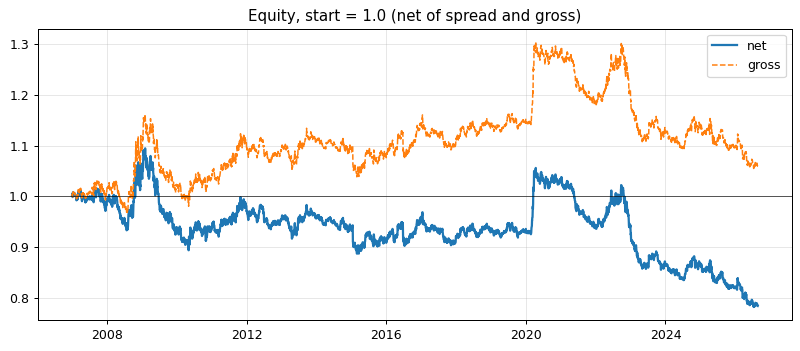

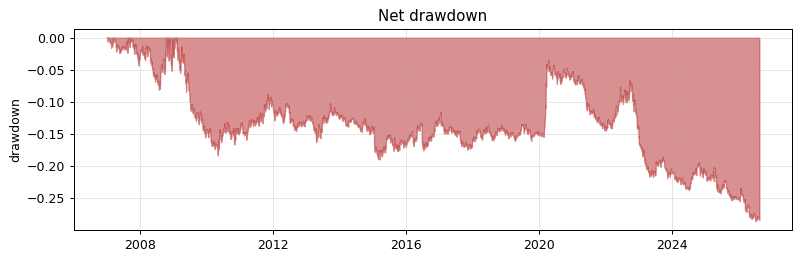

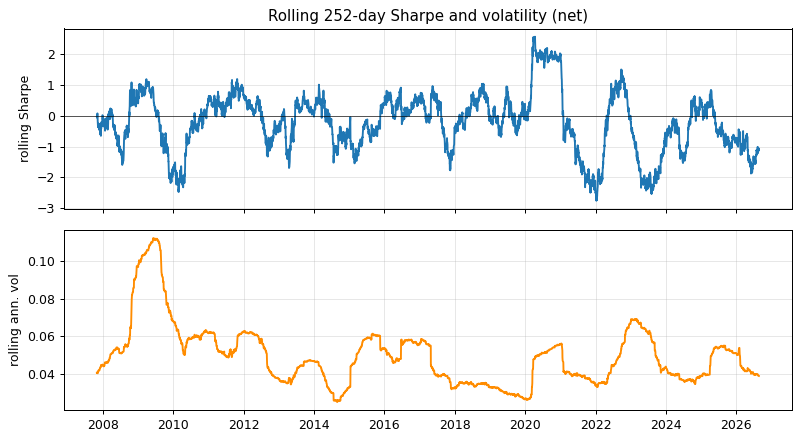

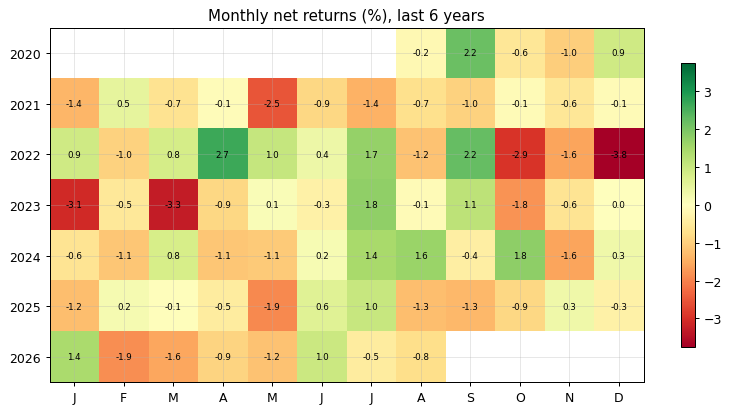

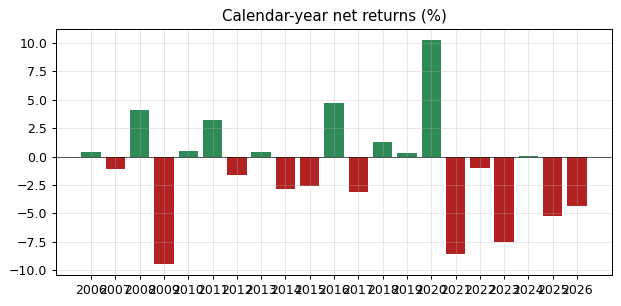

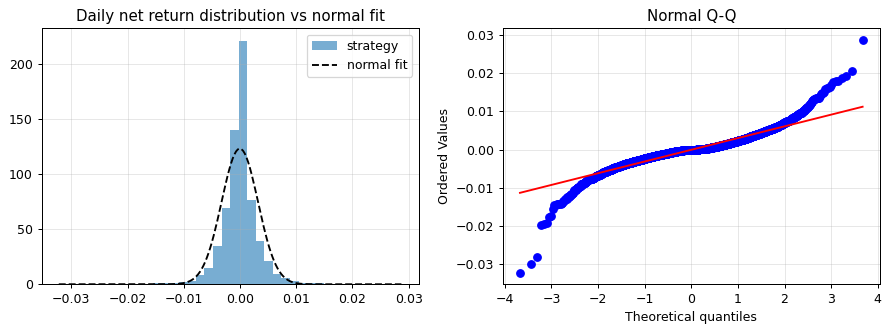

In [9]:
plot_equity(net, gross=gross, title="Equity, start = 1.0 (net of spread and gross)")
plt.show()
plot_drawdown(net, title="Net drawdown")
plt.show()
plot_rolling_risk(net, window=252, periods_per_year=ppy, title="Rolling 252-day Sharpe and volatility (net)")
plt.show()
plot_monthly_heatmap(net.loc[net.index >= net.index.max() - pd.DateOffset(years=6)], title="Monthly net returns (%), last 6 years")
plt.show()
plot_yearly_bars(net, title="Calendar-year net returns (%)")
plt.show()
plot_return_distribution(net, title="Daily net return distribution vs normal fit")
plt.show()

### 7.2 Exposure, turnover and cost decomposition

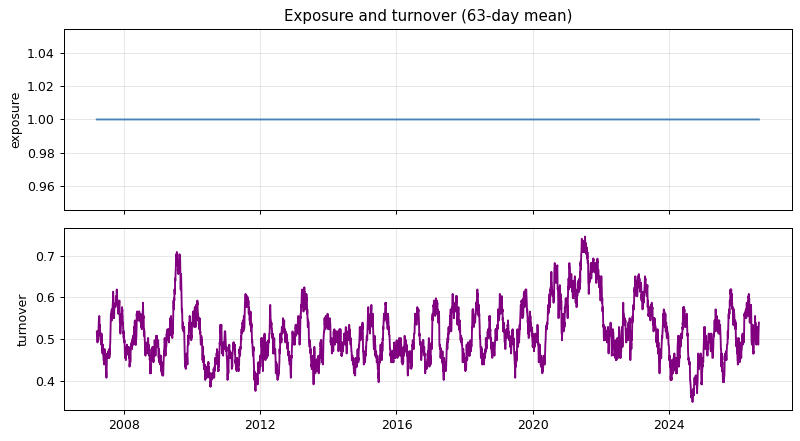

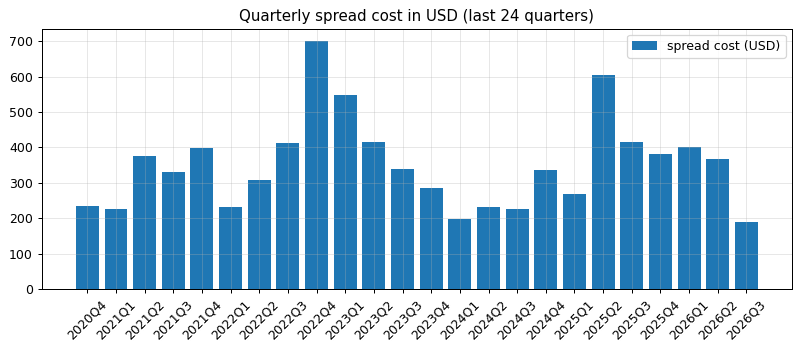

In [10]:
plot_exposure_turnover(exposure.rolling(63).mean(), turnover.rolling(63).mean(),
                       title="Exposure and turnover (63-day mean)")
plt.show()
monthly_cost = (cost * CAP / 1.0).resample("QE").sum().to_frame("spread cost (USD)")
monthly_cost.index = [str(i.to_period("Q")) for i in monthly_cost.index]
plot_cost_decomposition(monthly_cost.iloc[-24:], title="Quarterly spread cost in USD (last 24 quarters)")
plt.show()

### 7.3 Contribution per pair, per year and per volatility regime

The regime is the share of days on which the pair's EWMA-volatility regime ratio (`vol_regime`, computed with trailing information only) is above 1. Contribution is the pair's gross and net P&L in USD of the equal-weight book.

,gross_usd,cost_usd,net_usd
P1,-2487.0,5894.0,-8381.0
P2,4509.0,2575.0,1935.0
P3,644.0,4676.0,-4033.0
P4,-3764.0,5775.0,-9539.0
P5,-2376.0,6982.0,-9357.0
P6,12270.0,4164.0,8106.0


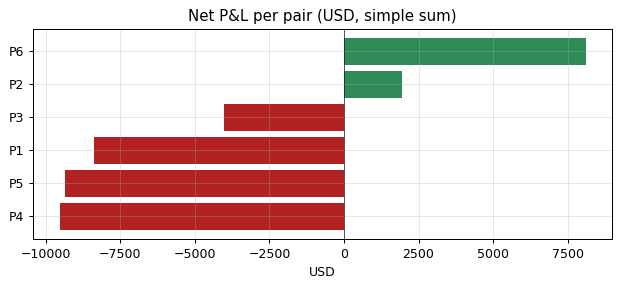

,days,gross_usd,cost_usd,net_usd
high_vol,2064,17342.0,12683.0,4658.0
low_vol,3774,-8546.0,17383.0,-25929.0


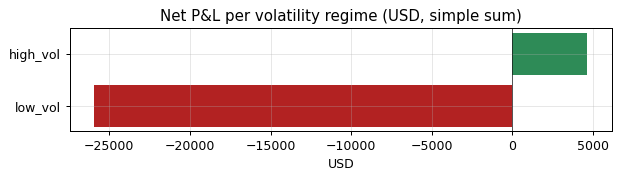

In [11]:
n_pairs = bt["gross_by_asset"].shape[1]
slot = CAP / n_pairs
by_pair = pd.DataFrame({"gross_usd": bt["gross_by_asset"].sum() * slot, "cost_usd": bt["cost_by_asset"].sum() * slot})
by_pair["net_usd"] = by_pair["gross_usd"] - by_pair["cost_usd"]
display(by_pair.round(0))
plot_bar_contribution(by_pair["net_usd"], title="Net P&L per pair (USD, simple sum)", xlabel="USD")
plt.show()

regime = pd.concat({a: frames[a]["vol_regime"] for a in frames}, axis=1).reindex(net.index)
hi = (regime > 1.0).mean(axis=1) > 0.5
reg_tbl = pd.DataFrame({"days": [int(hi.sum()), int((~hi).sum())],
                        "gross_usd": [gross[hi].sum() * CAP, gross[~hi].sum() * CAP],
                        "cost_usd": [cost[hi].sum() * CAP, cost[~hi].sum() * CAP]}, index=["high_vol", "low_vol"])
reg_tbl["net_usd"] = reg_tbl["gross_usd"] - reg_tbl["cost_usd"]
display(reg_tbl.round(0))
plot_bar_contribution(reg_tbl["net_usd"], title="Net P&L per volatility regime (USD, simple sum)", xlabel="USD")
plt.show()

### 7.4 Case-specific: feature importance and per-pair accuracy lift

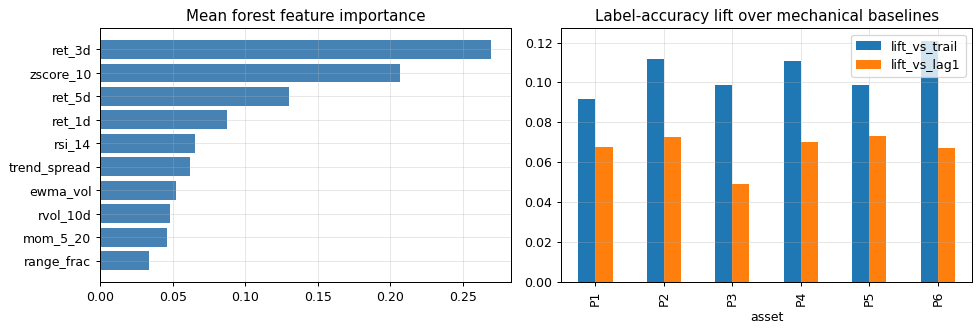

In [12]:
imp = pd.concat(importances, axis=1).mean(axis=1).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(imp.index, imp.values, color="steelblue")
axes[0].set_title("Mean forest feature importance")
lift = acc.drop(index="POOLED")[["lift_vs_trail", "lift_vs_lag1"]]
lift.plot.bar(ax=axes[1])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Label-accuracy lift over mechanical baselines")
fig.tight_layout()
plt.show()

## 8. Killing test: score what you trade, not the label

The label-accuracy number is not the P&L-relevant target. Four checks on the **traded** outcome:

1. **Signal vs next-day return**: correlation and hit rate of the signal against the return earned the following day.
2. **Block bootstrap** of the pooled gross Sharpe (blocks of 10 days preserve short-range dependence).
3. **Sign-permutation test**: shuffle each pair's signal sequence in time (keeping its long/short mix) 300 times and recompute the gross Sharpe; the share of shuffles at least as good as the real signal is a p-value.
4. **Cost sweep**: net Sharpe against a multiple of the observed spread.

,model signal
n,35028.0000
corr_signal_next_ret,0.0026
hit_rate_next_day,0.4868


pooled gross Sharpe (no costs): +0.07
block-bootstrap 5th-95th percentile: [-0.23, +0.40]; share of resamples above zero: 0.66
label accuracy lift over the lag-1 baseline (pooled): +0.067


sign-permutation: real gross Sharpe +0.07 | shuffled mean +0.01, 5th-95th [-0.34, +0.32] | share of shuffles at least as good: 0.403


,net_sharpe
0.00,0.073747
0.25,0.010723
0.50,-0.052299
1.00,-0.178301
2.00,-0.429840


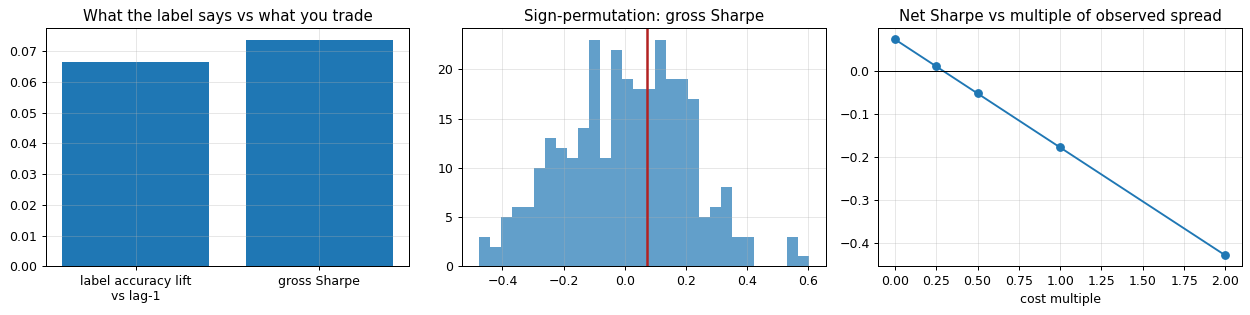

In [13]:
def signal_vs_next_day(frames, signals) -> pd.Series:
    sig = pd.concat([s.rename(a) for a, s in signals.items()], axis=1).stack()
    nxt = pd.concat([f["close"].pct_change().shift(-1).rename(a) for a, f in frames.items()], axis=1).stack()
    d = pd.concat([sig.rename("signal"), nxt.rename("next_ret")], axis=1).dropna()
    return pd.Series({"n": float(len(d)), "corr_signal_next_ret": float(d["signal"].corr(d["next_ret"])),
                      "hit_rate_next_day": float((np.sign(d["next_ret"]) == d["signal"]).mean())})


rel = signal_vs_next_day(frames, signals)
display(rel.to_frame("model signal").round(4))
ci = block_bootstrap_sharpe(gross, block=PARAMS["bootstrap_block"], n_boot=PARAMS["bootstrap_iters"], seed=0, periods_per_year=ppy)
print(f"pooled gross Sharpe (no costs): {sharpe_ratio(gross, ppy):+.2f}")
print(f"block-bootstrap 5th-95th percentile: [{ci['lo']:+.2f}, {ci['hi']:+.2f}]; share of resamples above zero: {ci['share_positive']:.2f}")
print(f"label accuracy lift over the lag-1 baseline (pooled): {acc.loc['POOLED', 'lift_vs_lag1']:+.3f}")

rng = np.random.default_rng(1)
nxt = {a: frames[a]["close"].pct_change().shift(-1).loc[s.index] for a, s in signals.items()}
perm = np.empty(PARAMS["permutation_draws"])
for b in range(len(perm)):
    g = pd.concat({a: pd.Series(rng.permutation(s.values), index=s.index) * nxt[a] for a, s in signals.items()}, axis=1).mean(axis=1).dropna()
    perm[b] = sharpe_ratio(g, ppy)
p_value = float((perm >= sharpe_ratio(gross, ppy)).mean())
print(f"sign-permutation: real gross Sharpe {sharpe_ratio(gross, ppy):+.2f} | shuffled mean {perm.mean():+.2f}, "
      f"5th-95th [{np.percentile(perm, 5):+.2f}, {np.percentile(perm, 95):+.2f}] | share of shuffles at least as good: {p_value:.3f}")

sweep_mult = pd.Series({m: sharpe_ratio(unit_backtest(frames, signals, m)["net"].dropna(), ppy) for m in PARAMS["cost_multiples"]},
                       name="net_sharpe")
display(sweep_mult.to_frame())
RESULTS.update({"corr": float(rel["corr_signal_next_ret"]), "hit_next_day": float(rel["hit_rate_next_day"]),
                "ci": [float(ci["lo"]), float(ci["hi"])], "share_positive": float(ci["share_positive"]),
                "perm_p": p_value, "cost_sweep": {str(k): float(v) for k, v in sweep_mult.items()}})

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].bar(["label accuracy lift\nvs lag-1", "gross Sharpe"], [acc.loc["POOLED", "lift_vs_lag1"], sharpe_ratio(gross, ppy)])
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("What the label says vs what you trade")
axes[1].hist(perm, bins=30, alpha=0.7)
axes[1].axvline(sharpe_ratio(gross, ppy), color="firebrick", lw=2)
axes[1].set_title("Sign-permutation: gross Sharpe")
sweep_mult.plot(ax=axes[2], marker="o")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_title("Net Sharpe vs multiple of observed spread")
axes[2].set_xlabel("cost multiple")
fig.tight_layout()
plt.show()

### 8.1 Synthetic-mode warning, and a multi-seed table

**Warning.** Synthetic prices contain no edge by construction. A bootstrap interval resamples *within one path*, so it cannot tell that the path itself was a lucky draw: a single synthetic path can show a clearly positive gross Sharpe by chance. Never read a synthetic-mode number as evidence. In synthetic mode the cell below repeats the whole pipeline over several independent seeds, which is the honest picture: gross Sharpe scatters around zero. In real-data mode the cell is skipped.

In [14]:
if SYNTHETIC:
    seeds = [7, 11, 13, 17, 19]
    rows = []
    small = dict(PARAMS, n_estimators=40)
    for sd in seeds:
        p = synthetic_daily_panel(SYNTH_ASSETS, n_days=N_SYNTH_DAYS, seed=sd)[CASE_COLS]
        fr = build_frames(p, PARAMS["sma_k"])
        sg, _ = walk_forward_rf(fr, small)
        b = unit_backtest(fr, sg)
        rows.append({"seed": sd, "gross_sharpe": sharpe_ratio(b["gross"].dropna(), ppy),
                     "net_sharpe": sharpe_ratio(b["net"].dropna(), ppy)})
    ms = pd.DataFrame(rows).set_index("seed")
    display(ms.round(2))
    print(f"mean gross Sharpe over {len(seeds)} seeds: {ms['gross_sharpe'].mean():+.2f} (std {ms['gross_sharpe'].std():.2f}); "
          "individual paths are noise, not edge")
else:
    print("real-data mode: multi-seed synthetic table skipped")

real-data mode: multi-seed synthetic table skipped


## 9. Capital sweep: does the answer depend on the initial equity?

The headline initial equity of 100,000 USD is an illustrative assumption. This section re-reads the same out-of-sample return streams at six equity levels. **Only the initial equity changes**; the signal, universe, spread cost and window are identical, nothing is retuned.

**What scales with capital:** dollar notional per pair and therefore dollar P&L and dollar costs. **What does not scale:** nothing else. This implementation has *no fixed per-order fees, no minimum ticket and no lot rounding*: costs are strictly proportional (spread / price), so every ratio (return, Sharpe, drawdown, cost share of capital) is identical at every capital level by construction. The sweep is still worth showing, because a real execution venue has minimum tickets and lots that would break this invariance at small size (see cases 03 and 08, where they do).

capital,5000,10000,25000,50000,100000,250000
gross_usd,294.62,589.25,1473.11,2946.23,5892.45,14731.13
cost_usd,1374.94,2749.88,6874.69,13749.39,27498.78,68746.94
net_usd,-1080.32,-2160.63,-5401.58,-10803.16,-21606.33,-54015.81
net_return,-21.61,-21.61,-21.61,-21.61,-21.61,-21.61
gross_return,5.89,5.89,5.89,5.89,5.89,5.89
cost_share,27.50,27.50,27.50,27.50,27.50,27.50
cagr,-1.05,-1.05,-1.05,-1.05,-1.05,-1.05
sharpe,-0.18,-0.18,-0.18,-0.18,-0.18,-0.18
max_drawdown,-28.56,-28.56,-28.56,-28.56,-28.56,-28.56
fixed_cost_usd,0.00,0.00,0.00,0.00,0.00,0.00


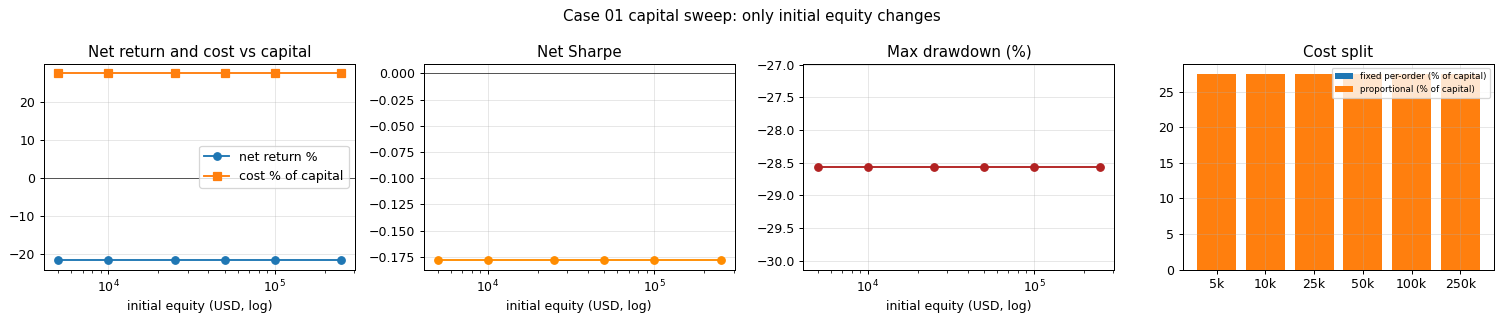

In [15]:
def run_at_capital(cap: float) -> Dict[str, float]:
    en, eg = scale_returns_to_equity(net, cap), scale_returns_to_equity(gross, cap)
    s = performance_summary(net, periods_per_year=ppy)
    cost_usd = float(eg.iloc[-1] - en.iloc[-1])
    return {"gross_usd": float(eg.iloc[-1] - cap), "cost_usd": cost_usd, "net_usd": float(en.iloc[-1] - cap),
            "net_return": float(en.iloc[-1] / cap - 1.0), "gross_return": float(eg.iloc[-1] / cap - 1.0),
            "cost_share": cost_usd / cap, "cagr": float(s["cagr"]), "sharpe": float(s["sharpe"]),
            "max_drawdown": float(s["max_drawdown"]), "fixed_cost_usd": 0.0, "proportional_cost_usd": cost_usd,
            "position_changes": RESULTS["n_position_changes"]}


_caps = [5_000, 100_000] if SYNTHETIC else list(PARAMS["capital_grid"])
cap_sweep = capital_sweep(run_at_capital, _caps)
show = cap_sweep.copy()
for col in ["net_return", "gross_return", "cost_share", "cagr", "max_drawdown"]:
    show[col] = (show[col] * 100).round(2)
display(show.round(2).set_index("capital").T)
RESULTS["capital_sweep"] = cap_sweep.round(6).to_dict("records")
plot_capital_sweep(cap_sweep, title="Case 01 capital sweep capital sweep: only initial equity changes")
plt.show()

## 10. Interpretation

**The label is the wrong target.** Pooled label accuracy is 68.4% against 61.8% for yesterday's return sign and 57.9% for the trailing slope: a lift of +6.7 points over the strongest mechanical baseline. But the traded outcome tells a different story: the signal's correlation with the next-day return is +0.0026, its next-day hit rate is 48.7%, and the pooled gross Sharpe is +0.07 with a 90% block-bootstrap interval of [-0.23, +0.40] (share of resamples above zero 0.66). The sign-permutation test agrees: 40.3% of shuffled signals did as well as the real one, so the gross result cannot be told from luck.

**Costs push a nothing into a loss.** Over 5,838 days the book made 5,892 USD gross on 100,000 USD of illustrative equity and paid 27,499 USD in observed spread (about 0.51 units of position change per pair per day), for a net of -21,606 USD: net Sharpe -0.18, CAGR -1.0%, maximum drawdown -28.6%. The cost sweep shows the net Sharpe crossing zero at about 0.25 times the observed spread, which no realistic execution achieves for a daily flip rule.

**Why the lift on the label is real but useless.** The label compares two overlapping five-day averages, so most of its sign is fixed by closes already known at time `t`. A rule that only copies yesterday's sign already scores above 60% on it; the forest adds a few points by learning that persistence. Persistence in the *smoothed* series is not persistence in the *next day's return*, which is what the position earns.

**Capital does not change the verdict.** Costs here are proportional (spread over price), so every ratio is identical from 5,000 to 250,000 USD (section 9). Only dollar amounts scale. The tag therefore stays "proxy target": this is a case about what the model was asked to predict, with cost model as a secondary finding.

## 11. The lesson

**Evaluate a model on the P&L-relevant target, and always compare label accuracy with the accuracy of a mechanical rule that uses only past prices.** A smoothed target can be "predicted" without any market insight. Checklist line: *the target must be the traded outcome, or a proven monotone proxy of it.*

## 12. What I would do differently

* Define the target as the traded return (or its sign over the holding period) from the start, and report accuracy only relative to the mechanical baseline built from the same inputs.
* Make the gross-before-cost signal check (correlation with next-day return and a block-bootstrap interval) the first gate before any sizing or portfolio machinery is built.
* Count independent decisions: a 5-row overlapping label on daily data has far fewer independent observations than rows, so report intervals, not point accuracies.
* Model execution honestly (spread, minimum tickets, financing) before looking at a Sharpe.

## 13. How to improve it (ideas, not claims)

* Predict next-day (or next-holding-period) return sign directly and score it with a proper scoring rule.
* Use a cost-aware label: trade only when the predicted move exceeds the spread.
* Add more independent history (more pairs, other asset classes) before adding model capacity.
* Judge by deflated Sharpe if the feature set or hyperparameters were chosen by looking at results.

## 14. FAQ

**Why is label accuracy so high if there is no edge?** The label is a function of the moving averages, which share four of five closes with yesterday's. A rule that only copies the recent slope already scores about 60%.

**Is there leakage in the walk-forward?** The purge equals the label's forward reach and an embargo is applied; the walk-forward window generator is unit-tested. The failure is a wrong target, not a leak.

**Does the result depend on capital?** No: this implementation has proportional costs only, so every ratio is identical across the capital sweep.

**Why does synthetic mode sometimes show an edge?** One random-walk path can show a positive Sharpe by chance; section 8.1 runs several seeds so you can see the scatter around zero.

**How general is this result?** It applies to the version tested: a simplified implementation with the parameter values in the settings cell. Change them and re-run the test to see whether the verdict holds.

## 15. References

* Lopez de Prado, M. (2018). *Advances in Financial Machine Learning.* Wiley (purging, embargo, labelling).
* Breiman, L. (2001). Random forests. *Machine Learning.*
* Bailey, D. H. and Lopez de Prado, M. (2014). The deflated Sharpe ratio. *Journal of Portfolio Management.*
* Politis, D. N. and Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association.*

## 16. Disclaimer

This notebook is educational. It documents a failed research idea with a simplified implementation and is not financial advice or a recommendation to trade. Past or hypothetical results do not predict future results. The code is provided as is.

In [16]:
import json
from pathlib import Path

if os.environ.get("AUTOPSY_RESULTS_JSON"):
    Path(os.environ["AUTOPSY_RESULTS_JSON"]).write_text(json.dumps(RESULTS, indent=2, default=str))
print("done")

done
